# Prática guiada · Classificação de imagens com a YOLO

Nesta prática vamos percorrer **o ciclo completo** de um projeto de classificação com a YOLO: escolher o dataset, treinar, entender o que foi salvo, ler as métricas, inspecionar os batches de treino e de validação, e fazer previsões.

Usamos o **MNIST** (dígitos escritos à mão), que a YOLO baixa sozinha. Mas o objetivo é que este notebook vire a **sua receita**: na próxima aula, você vai executá-lo de novo trocando **uma única linha**, a que diz qual é o dataset, para usar o seu.

| Etapa | O que acontece |
| --- | --- |
| 0. Preparação | instalar a biblioteca e conferir o ambiente |
| 1. O dataset | escolher o dataset pelo nome ou pelo caminho |
| 2. Treinar | uma chamada, com os hiperparâmetros da aula |
| 3. O dataset por dentro | onde a YOLO salvou e como ele está organizado |
| 4. O que o treino salvou | a pasta de resultados, arquivo por arquivo |
| 5. As métricas do treino | loss, acurácia e learning rate, época a época |
| 6. Os batches de treino | o que a rede realmente viu, com o aumento de dados |
| 7. A validação | batches de validação, matrizes de confusão e métricas por classe |
| 8. Prever imagens novas | usar o modelo treinado |
| 9. Guardar os resultados | copiar para o Google Drive |
| 10. Receita para o seu dataset | o que mudar na próxima aula |

**Como usar:** execute as células **em ordem**, lendo o texto antes de cada uma.

---
## 0. Preparação

**GPU:** no menu, *Ambiente de execução → Alterar o tipo de ambiente → GPU (T4)* → Salvar. Para o `mnist160` (160 imagens) a CPU dá conta; para o seu dataset, use a GPU. Faça isso **antes** de executar qualquer célula: trocar depois apaga o que já foi feito.

A instalação é uma linha. O `checks()` mostra as versões e se a GPU foi encontrada: procure por **CUDA** na saída. Se aparecer só **CPU**, o treino vai rodar no processador.

In [ ]:
!pip install -q ultralytics

import ultralytics
ultralytics.checks()

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


A célula abaixo só define funções para mostrar pastas, imagens e tabelas. Basta executá-la.

In [ ]:
#@title Funções de apoio (não precisa ler) { display-mode: "form" }
import random, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from PIL import Image
from IPython.display import Image as MostrarImagem, display

warnings.filterwarnings('ignore')
random.seed(0)

EXTENSOES = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}

def imagens_da_pasta(pasta):
    return sorted(p for p in Path(pasta).iterdir() if p.suffix.lower() in EXTENSOES)

def pasta_de_avaliacao(raiz):
    """A pasta que a YOLO usa como validação: val/, valid/, validation/ ou, se não houver, test/."""
    for nome in ['val', 'valid', 'validation', 'test']:
        if (Path(raiz) / nome).exists():
            return Path(raiz) / nome
    return None

def arvore(pasta, niveis=2, por_nivel=3, _prefixo='', _nivel=0):
    """Mostra a estrutura de pastas, com só alguns itens por nível."""
    if _nivel == 0:
        print(str(pasta) + '/')
    itens = sorted(Path(pasta).iterdir())
    pastas = [p for p in itens if p.is_dir()]
    arquivos = [p for p in itens if p.is_file()]
    for p in pastas[:por_nivel]:
        print(f'{_prefixo}├── {p.name}/')
        if _nivel + 1 < niveis:
            arvore(p, niveis, por_nivel, _prefixo + '│   ', _nivel + 1)
    if len(pastas) > por_nivel:
        print(f'{_prefixo}├── ... (+{len(pastas) - por_nivel} pastas)')
    if arquivos:
        nomes = ', '.join(a.name for a in arquivos[:3])
        print(f'{_prefixo}└── {nomes}{" ..." if len(arquivos) > 3 else ""} ({len(arquivos)} arquivos)')

def mostrar_grade(caminhos, titulos, colunas=10, tamanho=1.6):
    linhas = int(np.ceil(len(caminhos) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=(colunas * tamanho, linhas * tamanho * 1.3))
    for ax in np.atleast_1d(eixos).ravel():
        ax.axis('off')
    for ax, caminho, titulo in zip(np.atleast_1d(eixos).ravel(), caminhos, titulos):
        ax.imshow(Image.open(caminho).convert('RGB')); ax.set_title(titulo, fontsize=8)
    plt.tight_layout(); plt.show()

def mostrar_arquivos(pasta, padrao, largura=700):
    arquivos = sorted(Path(pasta).glob(padrao))
    if not arquivos:
        print(f'Nenhum arquivo "{padrao}" encontrado em {pasta}.')
    for a in arquivos:
        print(a.name)
        display(MostrarImagem(filename=str(a), width=largura))

print('Pronto.')

Pronto.


---
## 1. O dataset

O argumento `data=` aceita duas coisas:

- **O nome de um dataset que a YOLO conhece**, como `"mnist160"`, `"mnist"`, `"cifar10"` ou `"imagenette160"`. Ela baixa sozinha na primeira vez.
- **O caminho da pasta raiz de um dataset seu**, como `"/content/meu_dataset"`: a pasta que contém `train/` e `val/`.

Hoje usamos o `mnist160`: uma amostra de 160 imagens do MNIST (8 de cada dígito no treino e 8 no teste). É pequeno de propósito, para o treino ser rápido. **Na próxima aula, esta é a linha que você troca.**

In [ ]:
!unzip -q dataset_cls.zip -d /content
DATASET = "/content/dataset_cls"

---
## 2. Treinar

Uma única chamada treina o modelo. Cada argumento é um hiperparâmetro que já vimos na aula de treinamento:

| Argumento | Valor | O que faz |
| --- | --- | --- |
| `model` | `yolo26n-cls.pt` | a menor YOLO26 de classificação, **pré-treinada no ImageNet** |
| `data` | `DATASET` | o dataset (nome conhecido ou caminho da pasta raiz) |
| `epochs` | 30 | quantas vezes a rede passa por todo o conjunto de treino |
| `imgsz` | 224 | o tamanho em que as imagens entram na rede (os modelos de classificação foram pré-treinados em 224) |
| `batch` | 32 | quantas imagens por atualização dos pesos |
| `patience` | 10 | early stopping: para se a validação passar 10 épocas sem melhorar (o padrão é 100) |
| `seed` | 0 | fixa a aleatoriedade, para o resultado ser reproduzível |
| `fliplr` | 0.0 | desliga o espelhamento horizontal (explicado abaixo) |
| `project`, `name` | `"aula_yolo"`, `"treino"` | onde salvar: `aula_yolo/treino/` |

**Por que `fliplr=0.0`?** Por padrão, a YOLO espelha metade das imagens na horizontal durante o treino (`fliplr=0.5`). Isso é ótimo para fotos de folhas ou animais, mas não para dígitos: um "2" espelhado não é um "2". **No seu dataset, pense se espelhar faz sentido**: se não fizer, mantenha `fliplr=0.0`; se fizer, apague essa linha.

**Lendo a saída enquanto treina:**

- **"Dataset not found ... attempting download"**: a YOLO não achou o dataset e foi baixá-lo (só para nomes conhecidos).
- **"Dataset 'split=val' not found, using 'split=test' instead"**: o MNIST não tem pasta `val/`, então ela usa a `test/` para validar.
- **"optimizer=auto found, ignoring lr0"**: o otimizador está no automático e escolhe o learning rate sozinho.
- **A cada época**, uma barra com a **loss** de treino e, em seguida, uma linha da validação com **top1_acc** e **top5_acc**.
- No fim, a mensagem **"Results saved to ..."** diz onde ficou tudo.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n-cls.pt")    # pré-treinado no ImageNet

model.train(
    data=DATASET,
    epochs=30,
    imgsz=224,
    batch=8,
    patience=30,
    seed=0,
    fliplr=0.0,              # não espelhar: um dígito espelhado é outro desenho
    project="aula_yolo",
    name="treino",
    exist_ok=True,           # se treinar de novo, sobrescreve a mesma pasta
)

pasta_treino = Path(model.trainer.save_dir)
print('\nO treino foi salvo em:', pasta_treino)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_cls, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

---
## 3. O dataset por dentro

Quando você usa um nome conhecido, a YOLO salva o dataset nos **arquivos temporários** do Colab, numa pasta `datasets/`. Você pode navegar por ela no **ícone de pasta**, no painel à esquerda. Se `DATASET` for um caminho seu, a célula usa esse caminho.

In [ ]:
from ultralytics import settings

pasta_dataset = Path(DATASET) if Path(DATASET).exists() else Path(settings['datasets_dir']) / DATASET
print('O dataset está em:', pasta_dataset, '\n')
arvore(pasta_dataset, niveis=3, por_nivel=10)

O dataset está em: /content/dataset_cls 

/content/dataset_cls/
├── test/
│   ├── alta-ocupacao/
│   │   └── WhatsApp Image 2026-09-15 at 08.04.23 (1).jpeg, WhatsApp Image 2026-09-15 at 08.28.27.jpeg (2 arquivos)
│   ├── baixa-ocupacao/
│   │   └── gerada_imagem008.jpeg (1 arquivos)
│   ├── meio-termo/
│   │   └── WhatsApp Image 2026-09-15 at 08.06.39.jpeg, WhatsApp Image 2026-09-15 at 08.27.31.jpeg (2 arquivos)
├── train/
│   ├── alta-ocupacao/
│   │   └── WhatsApp Image 2026-09-07 at 14.17.04 (2).jpeg, WhatsApp Image 2026-09-07 at 14.21.36.jpeg, WhatsApp Image 2026-09-07 at 15.13.08 (1).jpeg ... (11 arquivos)
│   ├── baixa-ocupacao/
│   │   └── WhatsApp Image 2026-09-15 at 08.04.23 (2).jpeg, WhatsApp Image 2026-09-15 at 08.33.12.jpeg, gerada_image002.png ... (7 arquivos)
│   ├── meio-termo/
│   │   └── WhatsApp Image 2026-09-09 at 12.34.44 (3).jpeg, WhatsApp Image 2026-09-15 at 08.25.40.jpeg, WhatsApp Image 2026-09-15 at 08.25.58.jpeg ... (7 arquivos)
├── val/
│   ├── alta-ocupacao/


**Este é o formato da YOLO para classificação:**

- Uma pasta por conjunto: `train/` para treinar e `val/` para validar (aqui, como não há `val/`, a `test/` faz esse papel).
- Dentro de cada uma, **uma pasta por classe**. O **nome da pasta é o rótulo**: uma imagem é um "7" porque está na pasta `7/`. Não existe arquivo de rótulos.
- Os arquivos `.cache` são criados pela YOLO para carregar mais rápido nas próximas vezes; pode ignorar.

**É exatamente essa a estrutura que o seu dataset precisa ter.** Agora, quantas imagens há em cada classe?

In [ ]:
conjuntos = [c.name for c in sorted(pasta_dataset.iterdir()) if c.is_dir()]
contagem = {conj: {c.name: len(imagens_da_pasta(c)) for c in sorted((pasta_dataset / conj).iterdir()) if c.is_dir()}
            for conj in conjuntos}
tabela = pd.DataFrame(contagem)
tabela.index.name = 'classe'
tabela.loc['total'] = tabela.sum()
display(tabela)

,test,train,val
classe,,,
alta-ocupacao,2,11,2
baixa-ocupacao,1,7,1
meio-termo,2,7,2
total,5,25,5


Confira se as classes estão **equilibradas**. No seu dataset, se uma classe tiver muito mais imagens que outra, lembre da aula de métricas: a acurácia pode enganar, e vale olhar precisão e recall por classe (etapa 7).

Algumas imagens de cada classe, do treino:

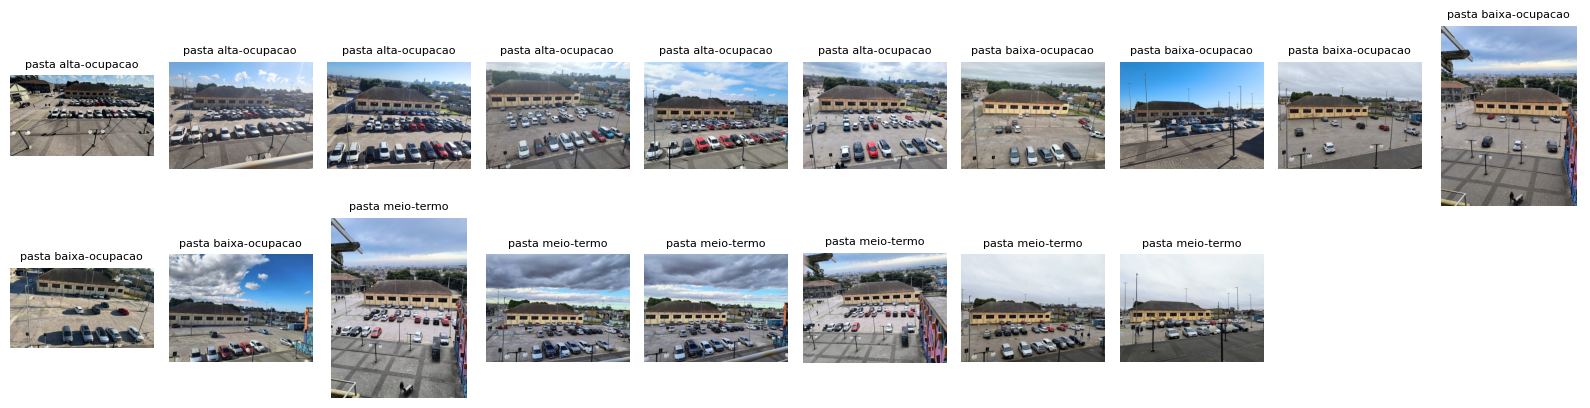

In [ ]:
classes = sorted(p for p in (pasta_dataset / 'train').iterdir() if p.is_dir())
por_classe = max(1, 20 // len(classes))
caminhos, titulos = [], []
for pasta_classe in classes:
    for img in imagens_da_pasta(pasta_classe)[:por_classe]:
        caminhos.append(img); titulos.append(f'pasta {pasta_classe.name}')
mostrar_grade(caminhos, titulos, colunas=10)

---
## 4. O que o treino salvou

Tudo do treino fica numa única pasta (aqui, `aula_yolo/treino/`):

In [ ]:
arvore(pasta_treino, niveis=2, por_nivel=30)

/content/runs/classify/aula_yolo/treino/
├── weights/
│   └── best.pt, last.pt (2 arquivos)
└── args.yaml, confusion_matrix.png, confusion_matrix_normalized.png ... (13 arquivos)


| Arquivo | O que é |
| --- | --- |
| `weights/best.pt` | o modelo da **melhor época** na validação. É o early stopping na prática, e é **ele** que se usa depois |
| `weights/last.pt` | o modelo da **última** época (útil para continuar um treino interrompido) |
| `results.csv` | a tabela com as métricas de cada época |
| `results.png` | as mesmas métricas em gráfico |
| `confusion_matrix.png` | matriz de confusão na validação, em contagens |
| `confusion_matrix_normalized.png` | a mesma, em proporções por classe |
| `train_batch*.jpg` | exemplos de batches **de treino**, como a rede os viu |
| `val_batch*_labels.jpg` | batches de validação com o **rótulo real** |
| `val_batch*_pred.jpg` | os mesmos batches com a **previsão** do modelo |
| `args.yaml` | **todos** os argumentos usados, inclusive os padrões que você não escreveu |

Vamos abrir cada um nas próximas etapas.

---
## 5. As métricas do treino

### 5.1 A tabela `results.csv`

Uma linha por época. As colunas:

| Coluna | Significado |
| --- | --- |
| `epoch` | o número da época |
| `time` | o tempo acumulado de treino, em segundos |
| `train/loss` | a **loss de treino** (cross-entropy) média na época |
| `metrics/accuracy_top1` | a **acurácia top-1** na validação: a classe mais provável é a correta? |
| `metrics/accuracy_top5` | a **acurácia top-5**: a correta está entre as 5 mais prováveis? |
| `val/loss` | a **loss de validação** |
| `lr/pg0`, `lr/pg1`, `lr/pg2` | o **learning rate** de cada grupo de pesos, época a época |

(Os nomes podem variar um pouco entre versões da biblioteca; as células abaixo procuram as colunas pelo nome.)

In [ ]:
res = pd.read_csv(pasta_treino / 'results.csv')
res.columns = [c.strip() for c in res.columns]
display(res.round(4))

,epoch,time,train/loss,metrics/accuracy_top1,metrics/accuracy_top5,val/loss,lr/pg0,lr/pg1,lr/pg2
0,1,4.0042,1.2838,0.2,1,1.2243,0.0004,0.0004,0.0004
1,2,5.6673,1.1201,0.0,1,1.1923,0.0008,0.0008,0.0008
2,3,6.6278,1.1732,0.0,1,1.1923,0.0012,0.0012,0.0012
3,4,7.7261,1.2646,0.8,1,0.8791,0.0013,0.0013,0.0013
4,5,8.9039,0.7147,0.8,1,0.8791,0.0012,0.0012,0.0012
5,6,10.0830,0.7104,0.8,1,0.6260,0.0012,0.0012,0.0012
6,7,11.0595,0.5831,0.8,1,0.6260,0.0011,0.0011,0.0011
7,8,12.3862,0.6266,0.8,1,0.4748,0.0011,0.0011,0.0011
8,9,13.6120,0.3771,0.8,1,0.4748,0.0011,0.0011,0.0011
9,10,14.9361,0.7051,0.8,1,0.5425,0.0010,0.0010,0.0010


### 5.2 As curvas

Três gráficos: as duas **losses** (treino e validação), as duas **acurácias** e o **learning rate**.

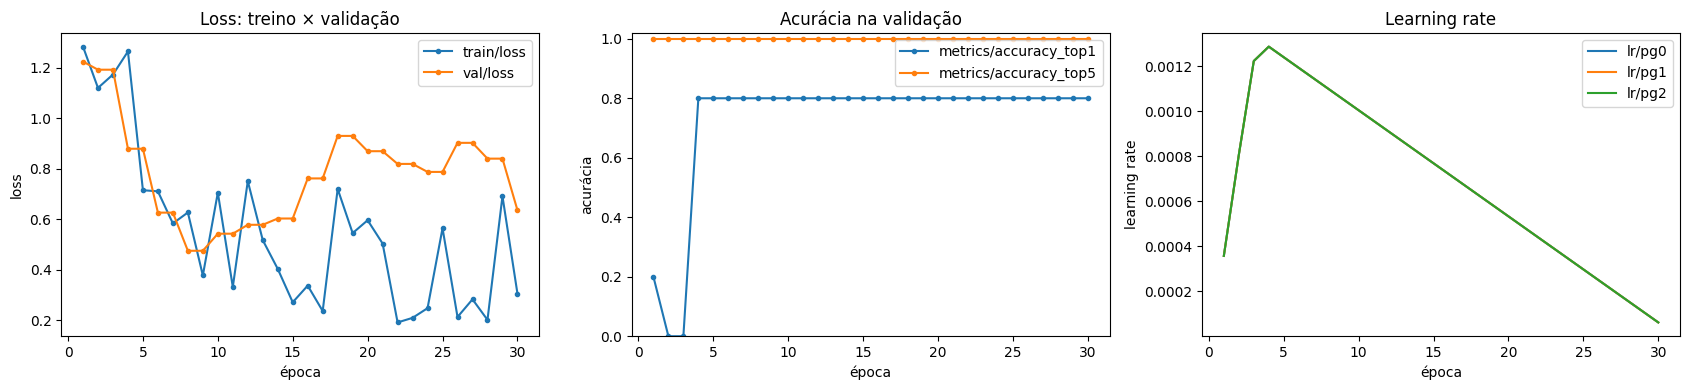

In [ ]:
col_loss = [c for c in res.columns if 'loss' in c]
col_acc = [c for c in res.columns if 'accuracy' in c or 'top1' in c or 'top5' in c]
col_lr = [c for c in res.columns if c.startswith('lr')]

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 4))
for c in col_loss:
    a1.plot(res['epoch'], res[c], 'o-', ms=3, label=c)
for c in col_acc:
    a2.plot(res['epoch'], res[c], 'o-', ms=3, label=c)
for c in col_lr:
    a3.plot(res['epoch'], res[c], label=c)
a1.set(xlabel='época', ylabel='loss', title='Loss: treino × validação'); a1.legend()
a2.set(xlabel='época', ylabel='acurácia', title='Acurácia na validação', ylim=(0, 1.02)); a2.legend()
a3.set(xlabel='época', ylabel='learning rate', title='Learning rate'); a3.legend()
plt.tight_layout(); plt.show()

**Como ler (a mesma leitura da aula de treinamento):**

- **Loss de treino caindo e de validação caindo junto:** a rede está aprendendo.
- **Loss de treino caindo e de validação subindo:** overfitting. A rede está decorando o treino.
- **As duas ainda caindo no fim:** dava para treinar mais épocas.
- **Top-5:** com poucas classes ela chega rápido a 100% e diz pouco. A métrica que importa é a **top-1**.
- **Learning rate:** a YOLO não o mantém fixo. Ele começa pequeno (*warmup*, um "aquecimento" nas primeiras épocas) e depois **diminui** até o fim do treino: passos maiores no começo, passos finos no final.

Com só 80 imagens de treino, espere curvas que oscilam bastante.

### 5.3 A melhor época

In [ ]:
col_top1 = [c for c in res.columns if 'top1' in c][0]
col_vloss = [c for c in res.columns if c.startswith('val') and 'loss' in c][0]
melhor_linha = res.loc[res[col_top1].idxmax()]

print(f'Épocas treinadas        : {len(res)} (de 30 pedidas)')
print(f'Melhor top-1 na validação: {melhor_linha[col_top1]:.1%}, na época {int(melhor_linha["epoch"])}')
print(f'Loss de validação mínima : {res[col_vloss].min():.4f}, na época {int(res.loc[res[col_vloss].idxmin(), "epoch"])}')
print(f'Top-1 na última época    : {res[col_top1].iloc[-1]:.1%}')

Épocas treinadas        : 30 (de 30 pedidas)
Melhor top-1 na validação: 80.0%, na época 4
Loss de validação mínima : 0.4748, na época 8
Top-1 na última época    : 80.0%


Se o treino parou antes das 30 épocas, foi o **early stopping** (`patience=10`): a validação passou 10 épocas sem melhorar. O `best.pt` guarda o modelo da melhor época, não o da última.

### 5.4 O gráfico pronto da YOLO

A YOLO também salva todas essas curvas num único gráfico, o `results.png`:

results.png


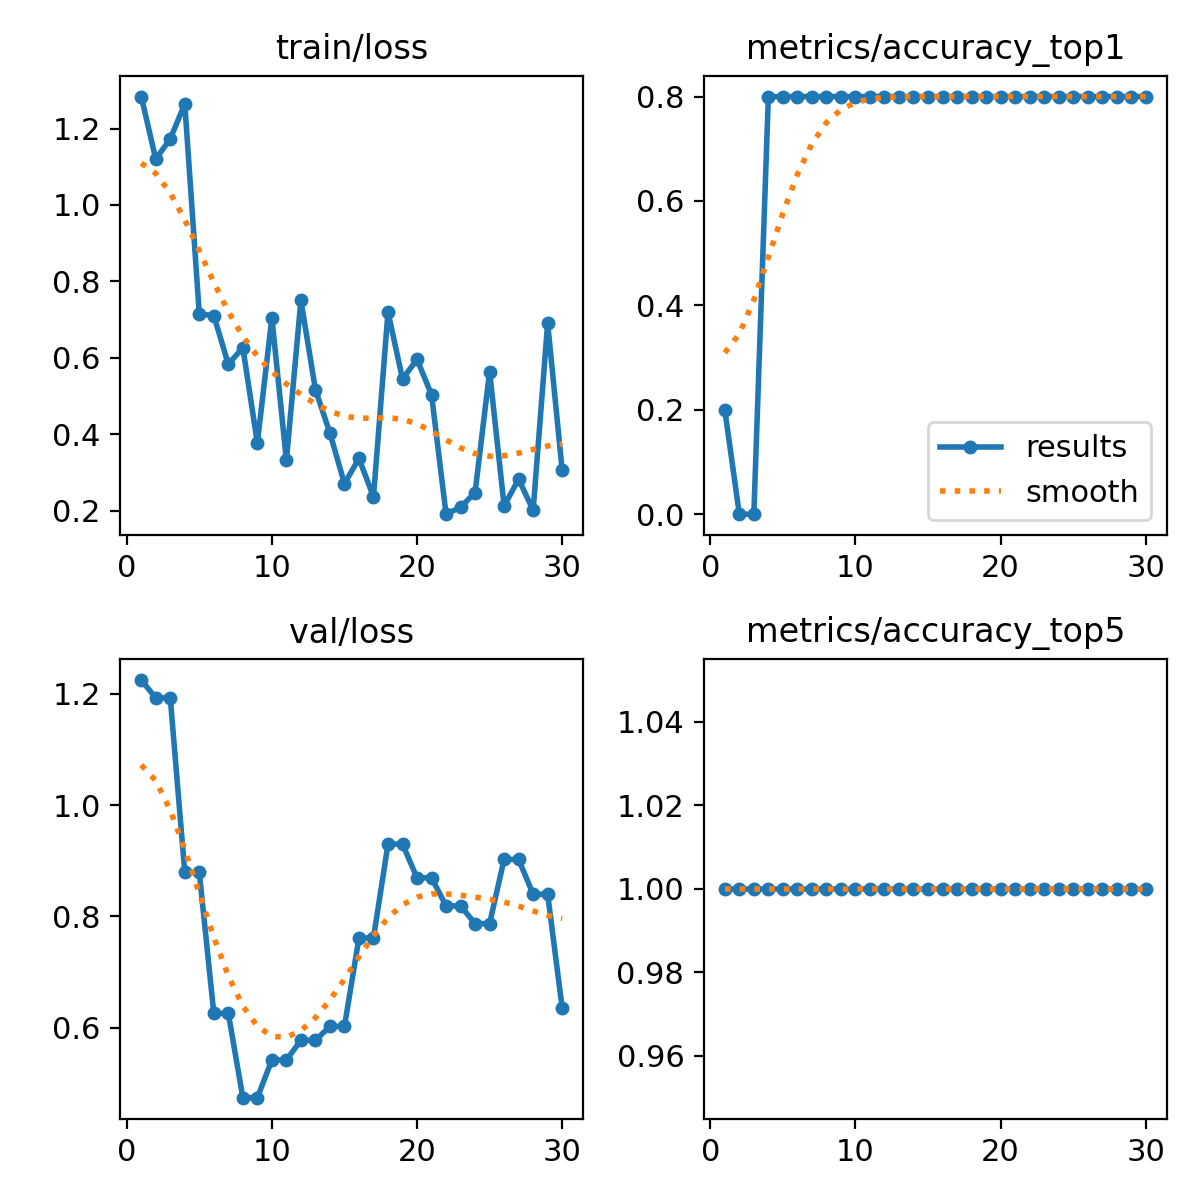

In [ ]:
mostrar_arquivos(pasta_treino, 'results.png', largura=900)

---
## 6. Os batches de treino

Durante as primeiras épocas, a YOLO salva algumas imagens de **batches de treino** (`train_batch*.jpg`). Elas mostram exatamente o que a rede recebeu, já **depois do aumento de dados** (*data augmentation*): as transformações aleatórias aplicadas a cada imagem para a rede não ver sempre a mesma coisa. Cada imagem do mosaico traz o rótulo da classe.

train_batch0.jpg


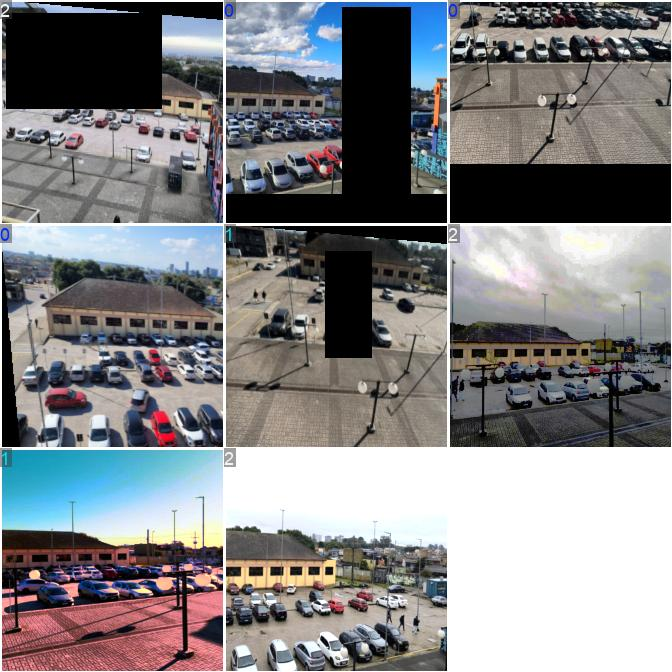

train_batch1.jpg


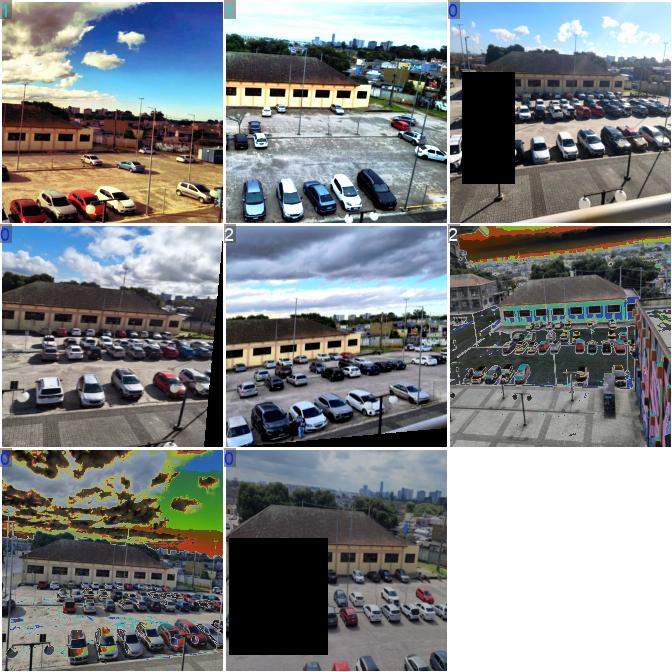

train_batch2.jpg


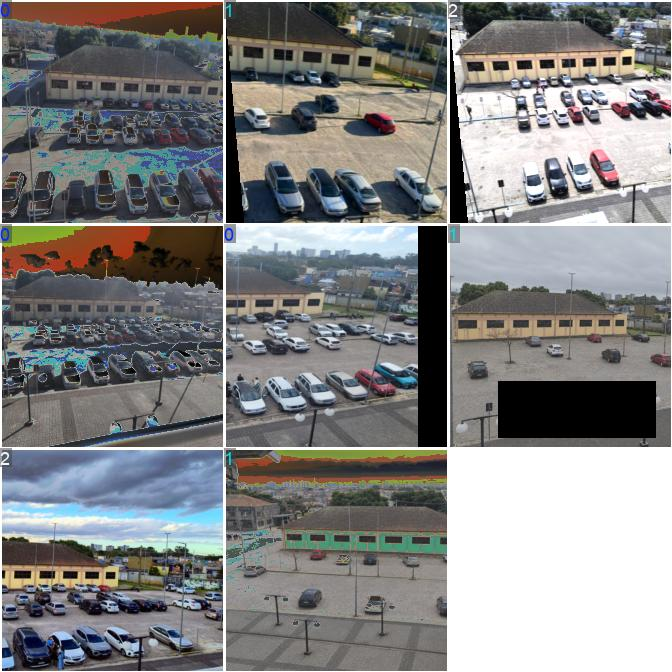

train_batch80.jpg


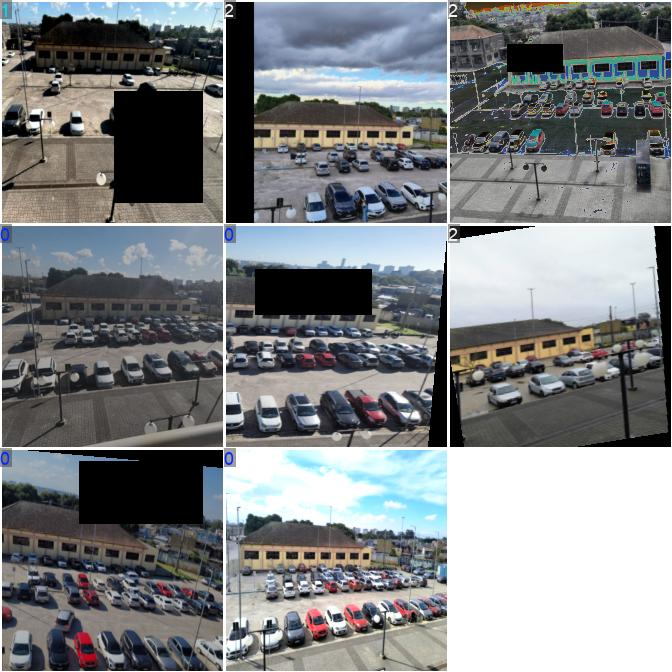

train_batch81.jpg


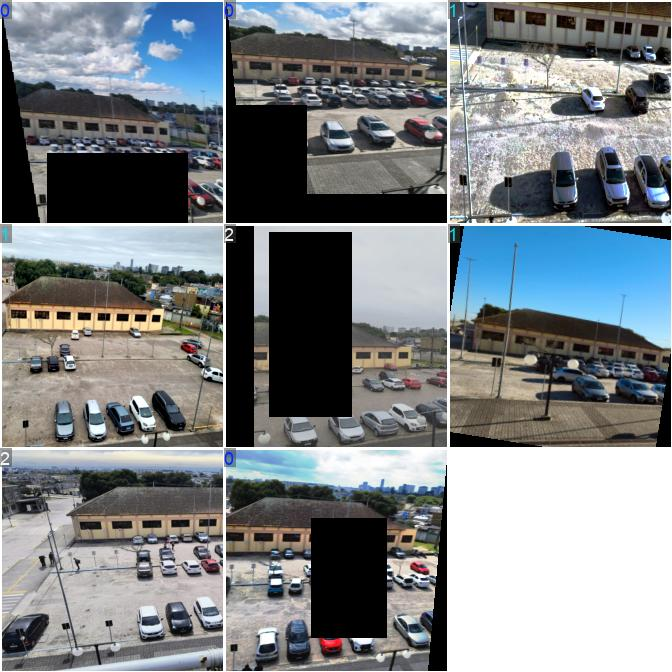

train_batch82.jpg


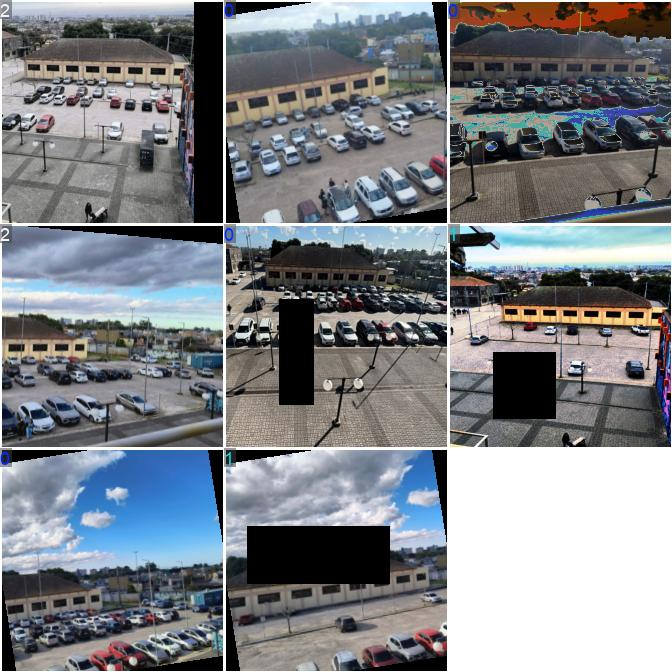

In [ ]:
mostrar_arquivos(pasta_treino, 'train_batch*.jpg', largura=750)

**O que observar:** as imagens não são idênticas às originais da etapa 3. Algumas aparecem recortadas, ampliadas, com cores ou contraste alterados, ou com retângulos apagados. Isso é o aumento de dados: a rede raramente vê duas vezes a mesma imagem exata, o que ajuda contra o overfitting. Repare também que **nenhum dígito aparece espelhado**, porque desligamos o `fliplr`.

Quais transformações foram usadas, e com que intensidade? Estão no `args.yaml`, junto com todos os outros argumentos:

In [ ]:
args = yaml.safe_load(open(pasta_treino / 'args.yaml'))

treino = ['model', 'data', 'epochs', 'imgsz', 'batch', 'patience', 'seed', 'optimizer', 'lr0', 'lrf', 'warmup_epochs', 'pretrained']
aumento = ['auto_augment', 'fliplr', 'flipud', 'hsv_h', 'hsv_s', 'hsv_v', 'scale', 'translate', 'degrees', 'erasing']

print('TREINO')
for k in treino:
    if k in args: print(f'  {k:14s} = {args[k]}')
print('\nAUMENTO DE DADOS')
for k in aumento:
    if k in args: print(f'  {k:14s} = {args[k]}')

TREINO
  model          = yolo26n-cls.pt
  data           = /content/dataset_cls
  epochs         = 30
  imgsz          = 224
  batch          = 8
  patience       = 30
  seed           = 0
  optimizer      = auto
  lr0            = 0.01
  lrf            = 0.01
  warmup_epochs  = 3.0
  pretrained     = True

AUMENTO DE DADOS
  auto_augment   = randaugment
  fliplr         = 0.0
  flipud         = 0.0
  hsv_h          = 0.015
  hsv_s          = 0.7
  hsv_v          = 0.4
  scale          = 0.5
  translate      = 0.1
  degrees        = 0.0
  erasing        = 0.4


| Argumento | O que faz |
| --- | --- |
| `auto_augment` | uma política automática de transformações (`randaugment`: sorteia transformações a cada imagem) |
| `fliplr`, `flipud` | probabilidade de espelhar na horizontal e na vertical |
| `hsv_h`, `hsv_s`, `hsv_v` | variações aleatórias de matiz, saturação e brilho |
| `scale`, `translate`, `degrees` | ampliar ou reduzir, deslocar, girar |
| `erasing` | probabilidade de **apagar** um retângulo da imagem, forçando a rede a não depender de um único detalhe |

Repare também em `optimizer` e `lr0`: com `optimizer=auto`, o `lr0` que aparece aqui não foi o usado. **No seu dataset, pense quais transformações fazem sentido**: se as fotos sempre têm a mesma orientação, espelhar ou girar pode atrapalhar.

---
## 7. A validação

### 7.1 Batches de validação: o real × o previsto

A YOLO também salva batches da **validação**, em pares: `val_batch*_labels.jpg` mostra cada imagem com o **rótulo real**, e `val_batch*_pred.jpg` mostra **as mesmas imagens** com a **previsão** do modelo. Compare os dois, imagem por imagem.

RÓTULO REAL: val_batch0_labels.jpg


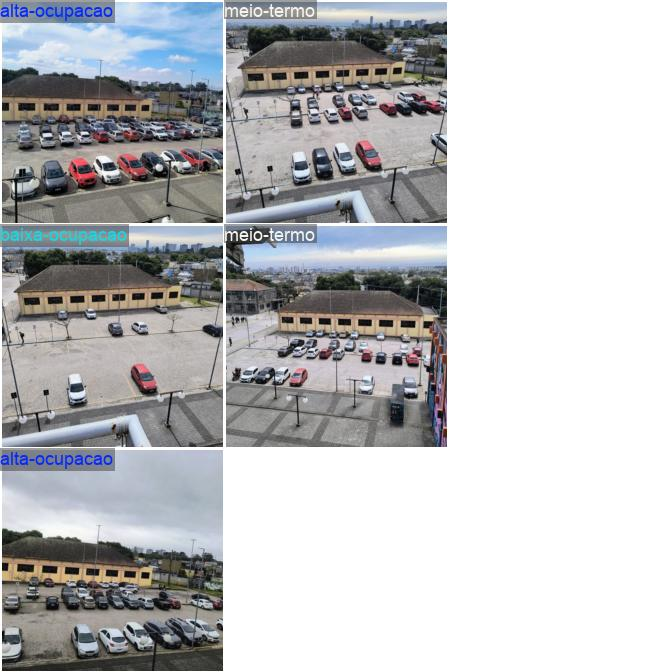

PREVISÃO DO MODELO: val_batch0_pred.jpg


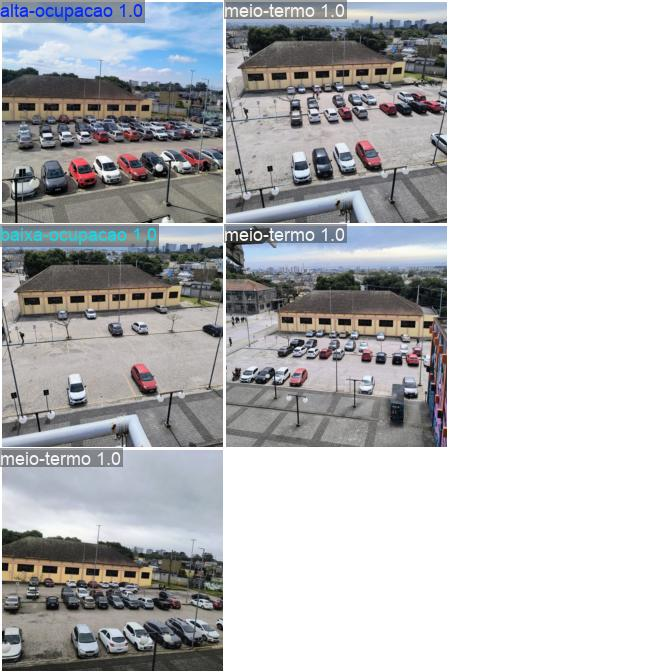

In [ ]:
for rotulos in sorted(pasta_treino.glob('val_batch*_labels.jpg')):
    previsoes = pasta_treino / rotulos.name.replace('_labels', '_pred')
    print('RÓTULO REAL:', rotulos.name)
    display(MostrarImagem(filename=str(rotulos), width=650))
    if previsoes.exists():
        print('PREVISÃO DO MODELO:', previsoes.name)
        display(MostrarImagem(filename=str(previsoes), width=650))

**O que observar:** os erros costumam aparecer em imagens ambíguas, como um "4" que parece "9" ou um "7" que parece "1". São erros que uma pessoa também poderia cometer?

### 7.2 Matrizes de confusão

A matriz em **contagens** mostra quantas imagens de cada classe real (linhas ou colunas, conforme o rótulo dos eixos) foram previstas como cada classe. A **normalizada** mostra o mesmo em proporções, o que facilita comparar classes com quantidades diferentes de imagens. A diagonal são os acertos; tudo fora dela são confusões.

confusion_matrix.png


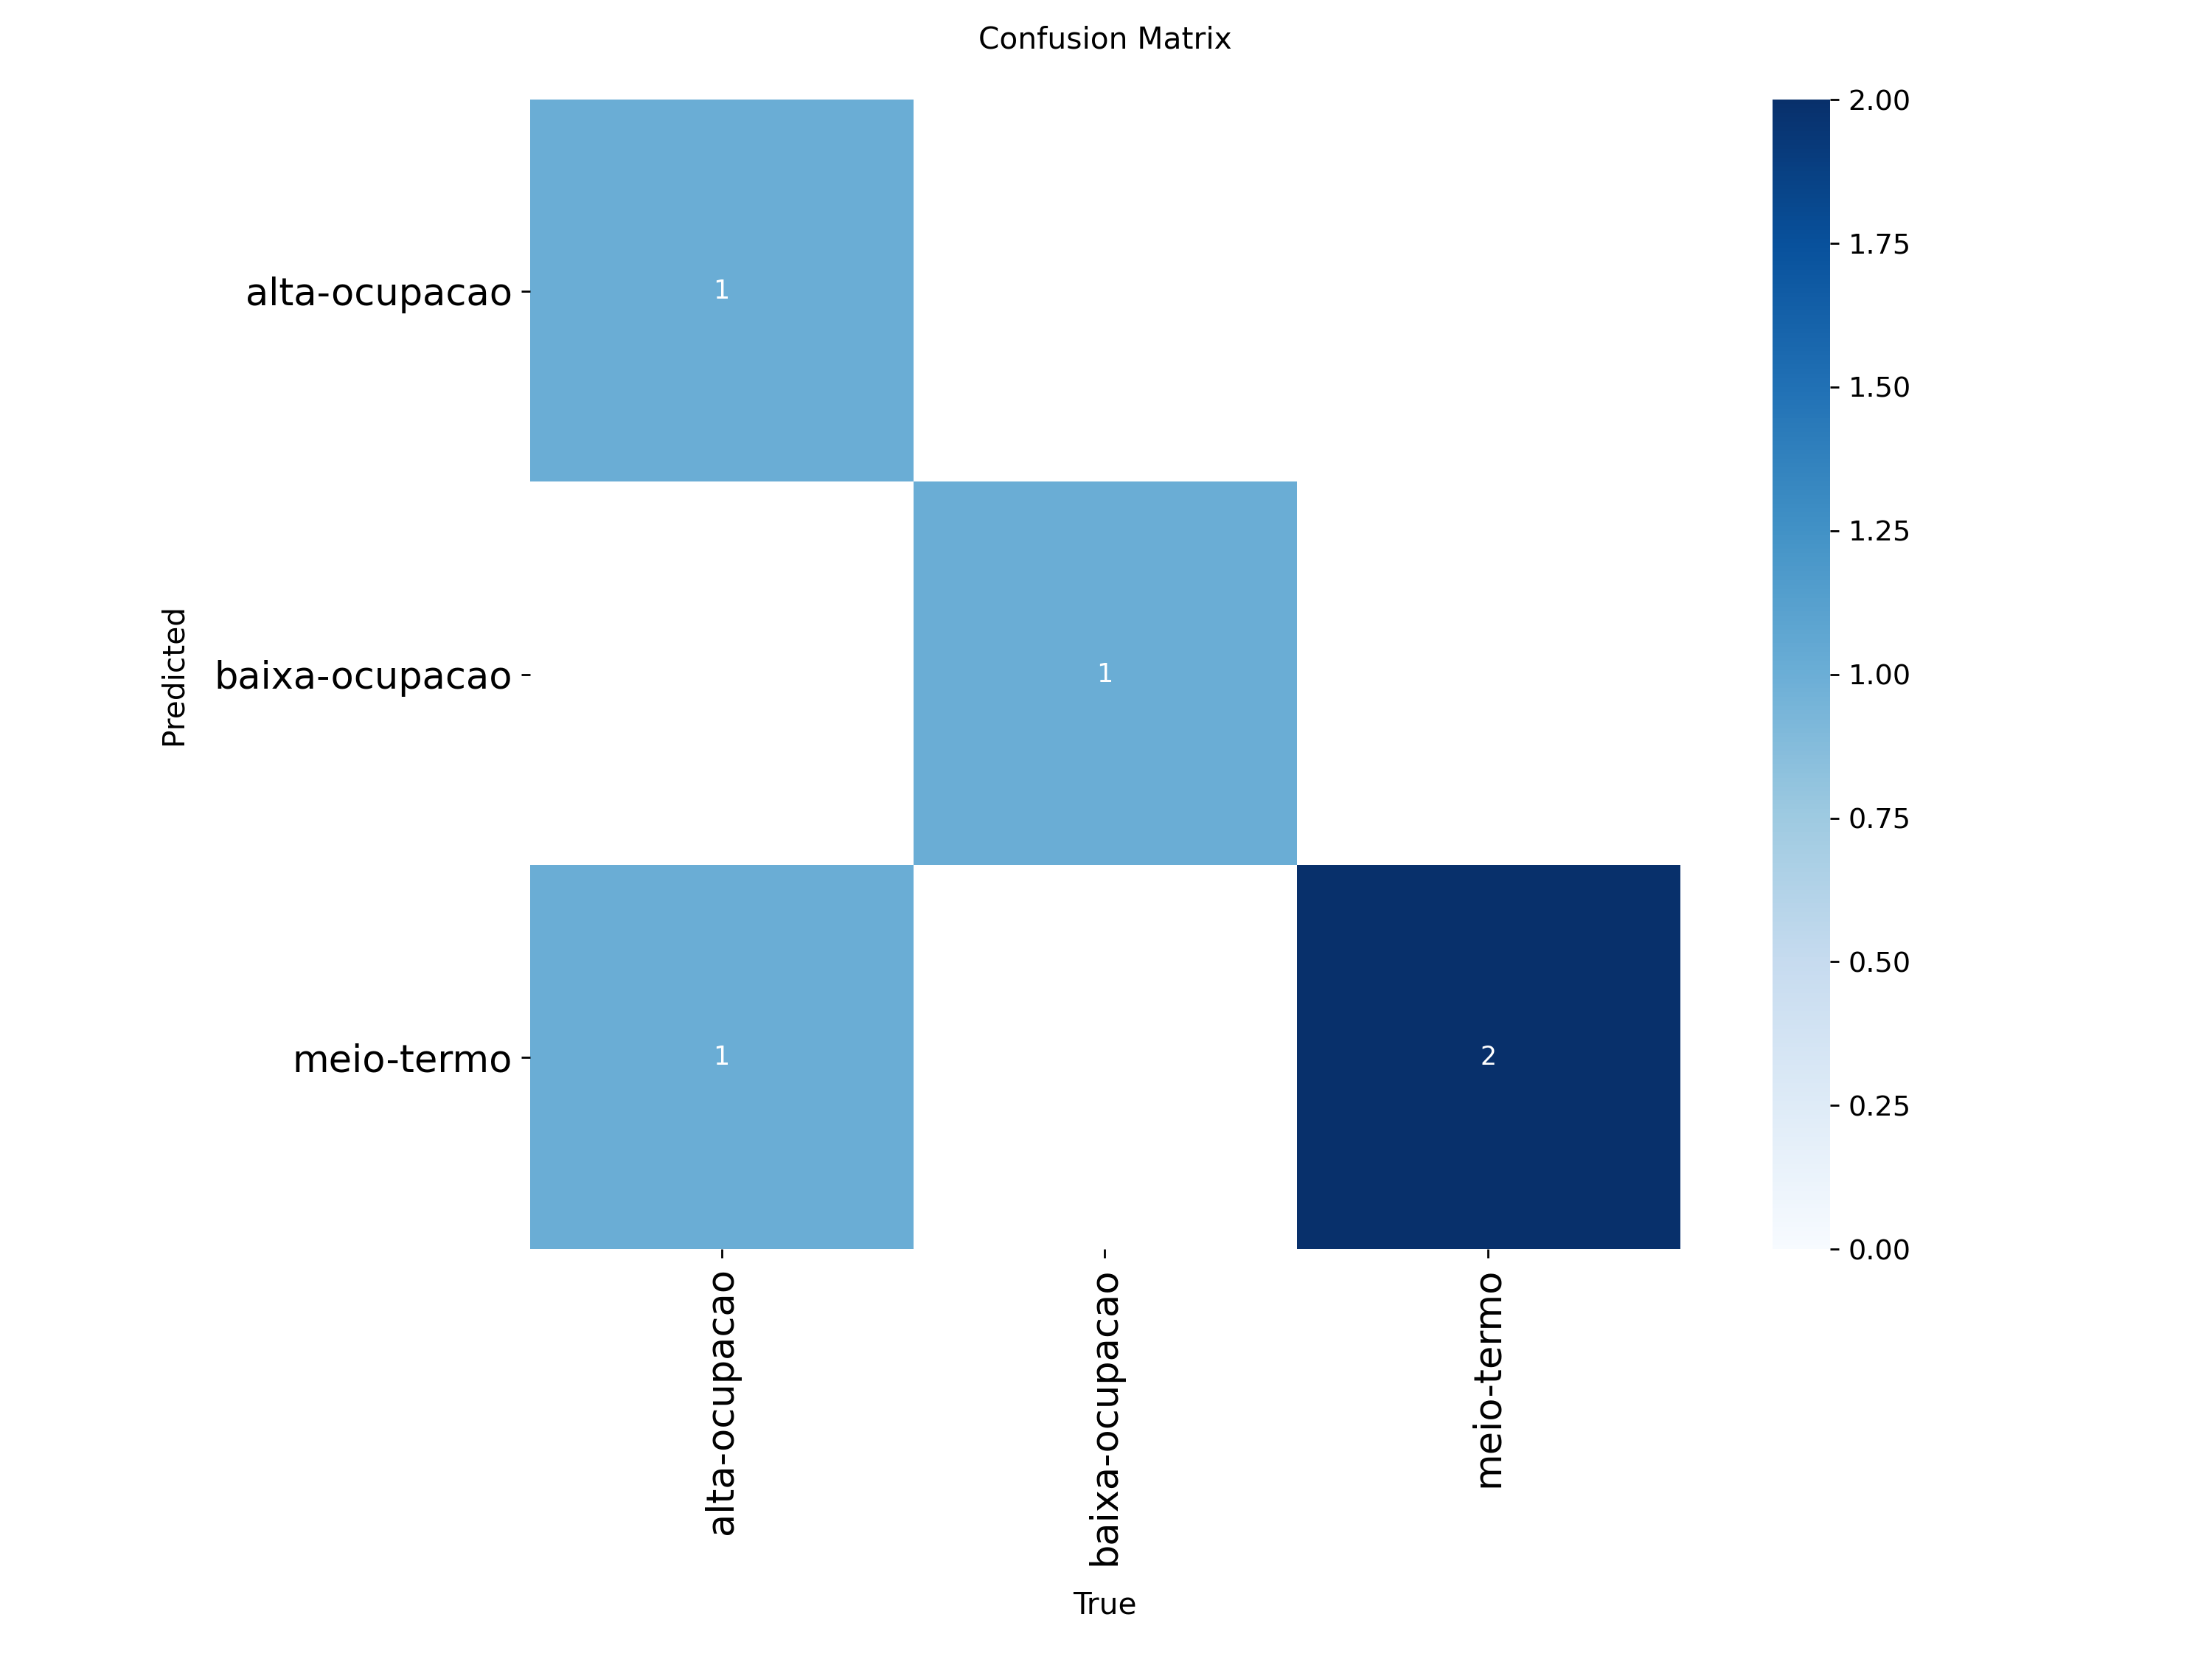

confusion_matrix_normalized.png


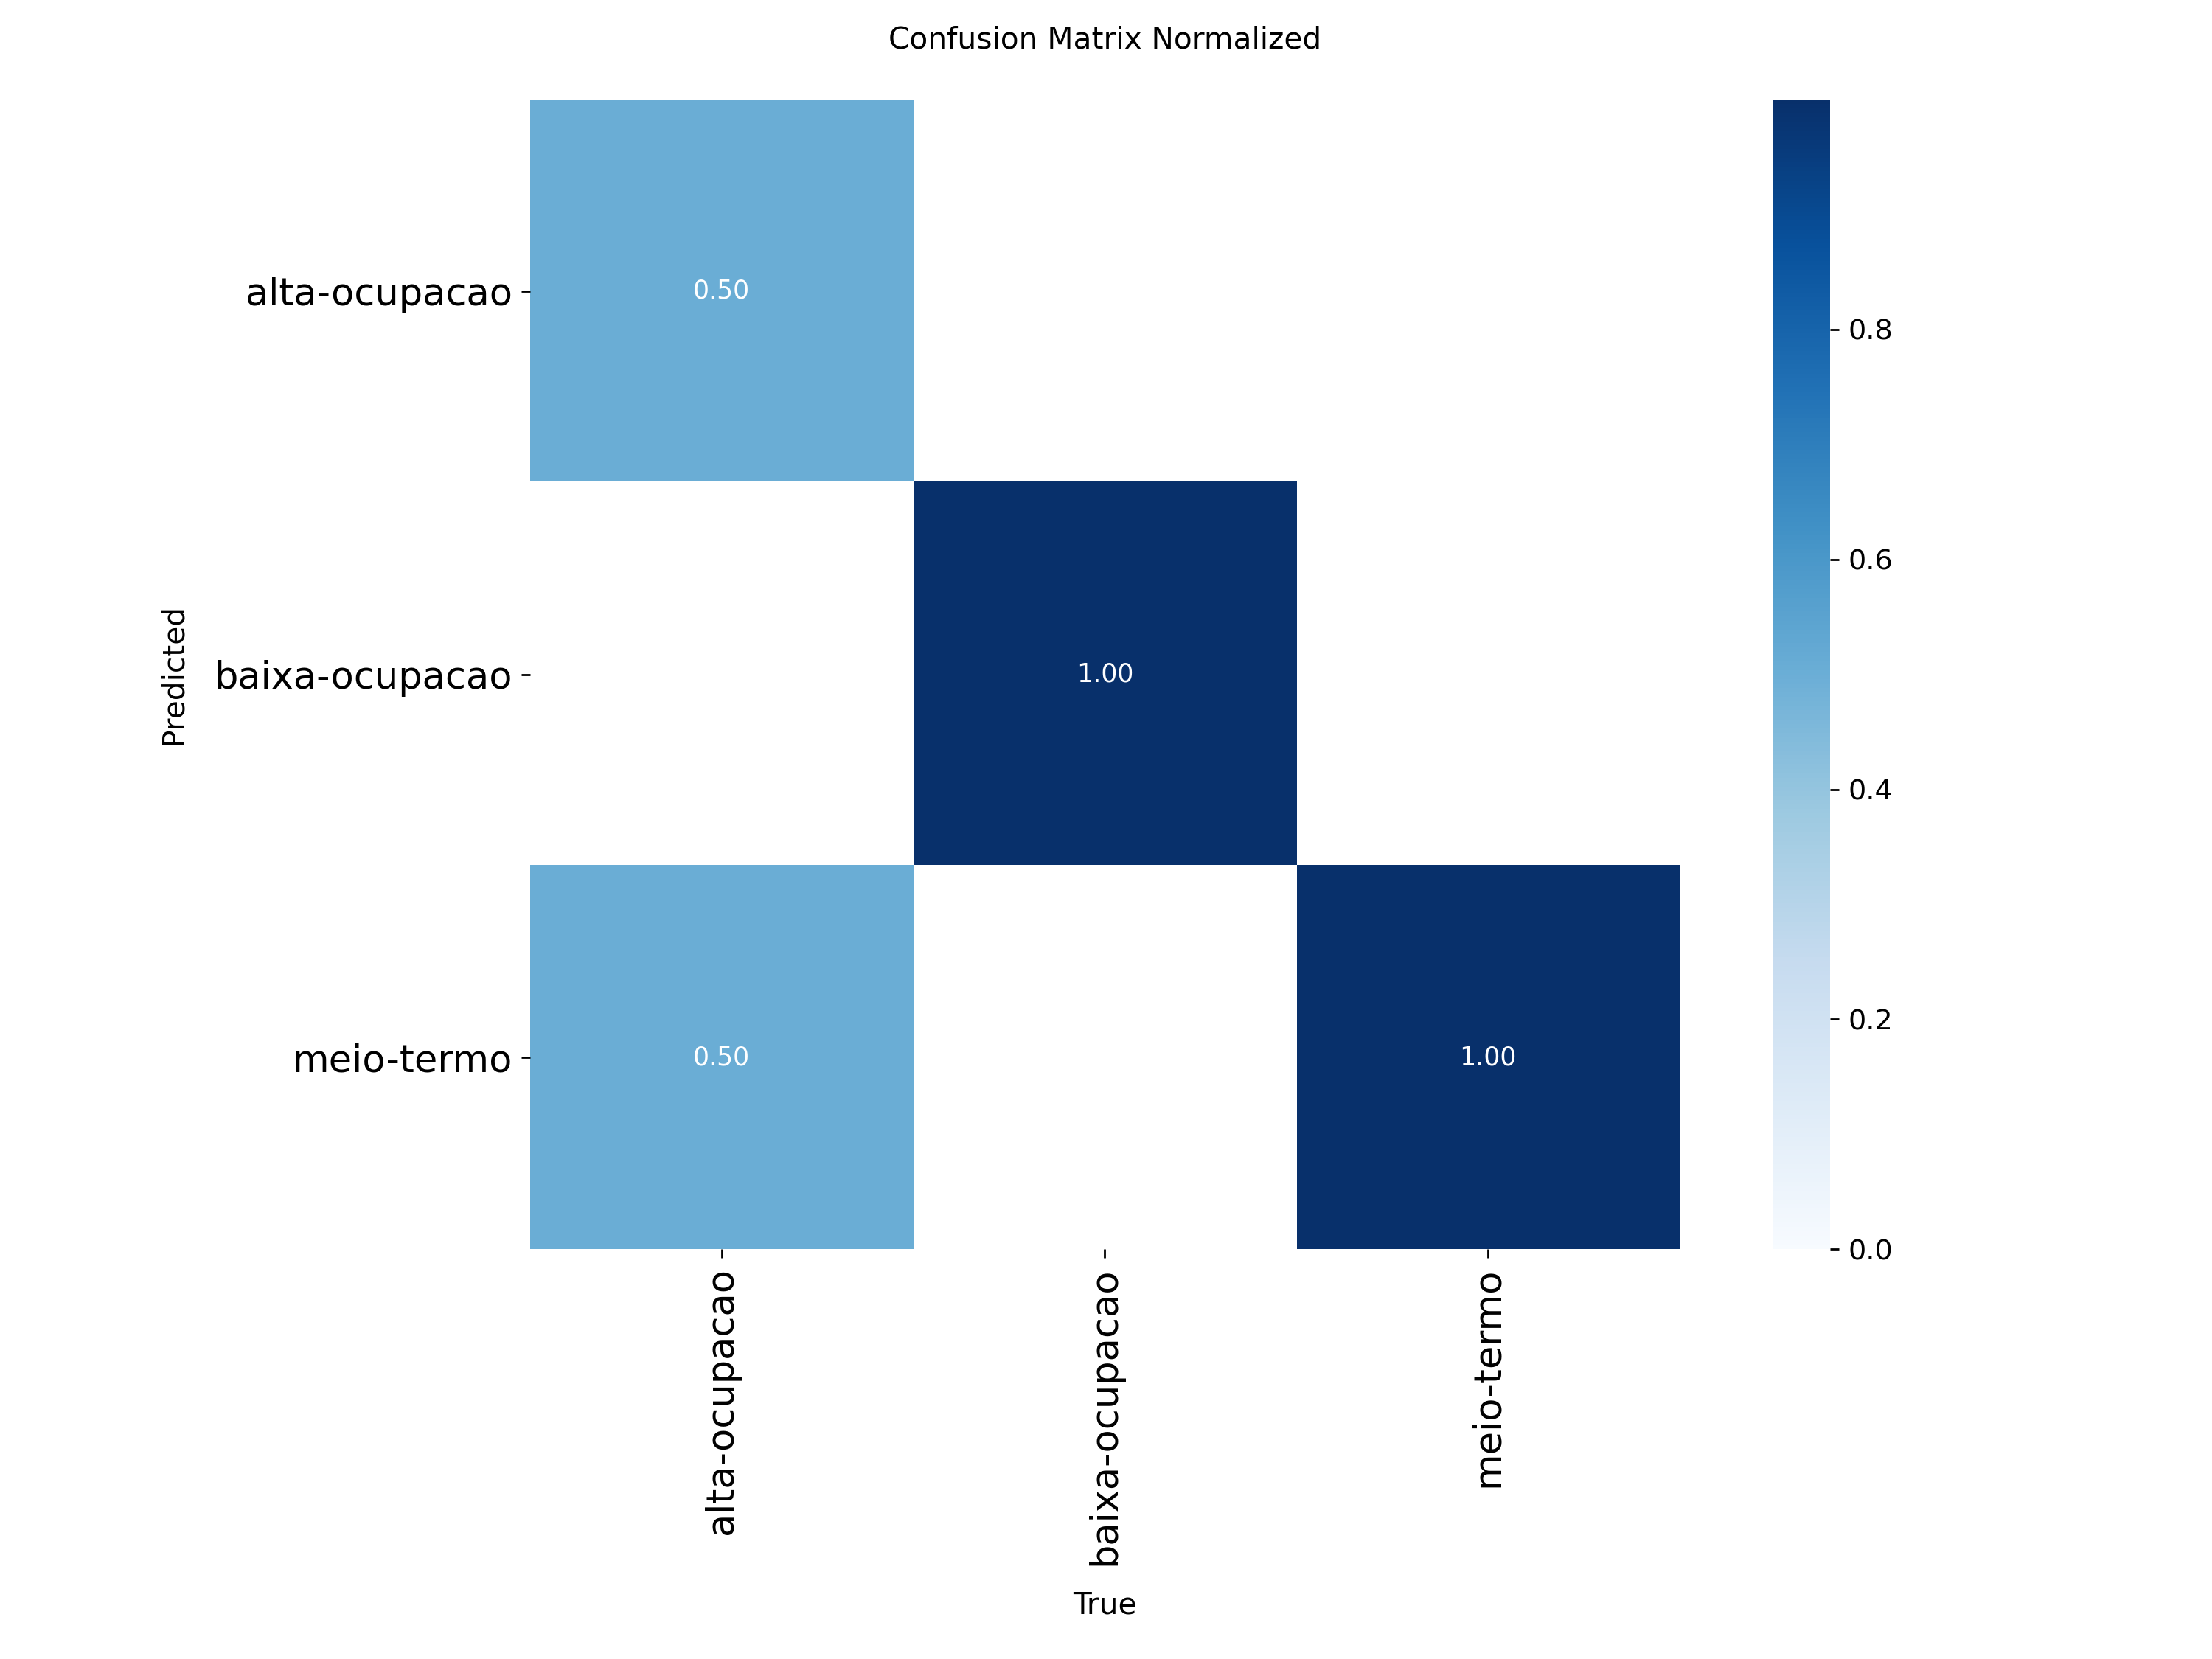

In [ ]:
mostrar_arquivos(pasta_treino, 'confusion_matrix*.png', largura=600)

### 7.3 As métricas finais do melhor modelo

Carregamos o `best.pt` e o avaliamos de novo no conjunto de validação:

In [ ]:
melhor = YOLO(pasta_treino / 'weights' / 'best.pt')
metricas = melhor.val(data=DATASET, imgsz=224, verbose=False)

print(f'acurácia top-1: {metricas.top1:.1%}')
print(f'acurácia top-5: {metricas.top5:.1%}')

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset_cls/train... found 25 images in 3 classes ✅ 
val: /content/dataset_cls/val... found 5 images in 3 classes ✅ 
test: /content/dataset_cls/test... found 5 images in 3 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3034.2±482.7 MB/s, size: 983.3 KB)
val: Scanning /content/dataset_cls/val... 5 images, 0 corrupt: 100% ━━━━━━━━━━━━ 5/5 1.5Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 1/1 3.9it/s 0.3s
                   all        0.8          1
Speed: 0.1ms preprocess, 7.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
acurácia top-1: 80.0%
acurácia top-5: 100.0%


### 7.4 Precisão, recall e F1 por classe

O resumo da YOLO traz top-1 e top-5. Para ver **precisão, recall e F1 de cada classe**, como na aula de métricas, prevemos todas as imagens da validação e usamos o scikit-learn:

In [ ]:
from sklearn.metrics import classification_report

pasta_val = pasta_de_avaliacao(pasta_dataset)
indice = {nome: i for i, nome in melhor.names.items()}

caminhos, y_real = [], []
for pasta_classe in sorted(p for p in pasta_val.iterdir() if p.is_dir()):
    for img in imagens_da_pasta(pasta_classe):
        caminhos.append(img); y_real.append(indice[pasta_classe.name])

y_prev = [r.probs.top1 for r in melhor.predict(caminhos, imgsz=224, verbose=False, stream=True)]
nomes = [melhor.names[i] for i in range(len(melhor.names))]

print(f'Avaliando {len(caminhos)} imagens de {pasta_val}\n')
print(classification_report(y_real, y_prev, target_names=nomes, digits=2, zero_division=0))

Avaliando 5 imagens de /content/dataset_cls/val

                precision    recall  f1-score   support

 alta-ocupacao       1.00      0.50      0.67         2
baixa-ocupacao       1.00      1.00      1.00         1
    meio-termo       0.67      1.00      0.80         2

      accuracy                           0.80         5
     macro avg       0.89      0.83      0.82         5
  weighted avg       0.87      0.80      0.79         5



**Como ler (aula de métricas):**

- **Precisão** de uma classe: quando o modelo diz que é ela, quantas vezes acerta?
- **Recall**: das imagens que são dessa classe, quantas o modelo encontrou?
- **F1**: equilíbrio entre as duas.
- **support**: quantas imagens da classe havia na validação. Com poucas imagens por classe, um único erro muda muito a métrica.

**Para pensar:** aqui a validação foi feita no `test/`, que a YOLO também usou para escolher o `best.pt`. Por isso essa nota tende a ser um pouco otimista. No seu dataset, tenha `train/`, `val/` **e** `test/`, e só avalie no `test/` uma vez, no fim.

In [ ]:
metricas_teste = melhor.val(data=DATASET, split="test", imgsz=224)
print(f'top-1 no teste: {metricas_teste.top1:.1%}')

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset_cls/train... found 25 images in 3 classes ✅ 
val: /content/dataset_cls/val... found 5 images in 3 classes ✅ 
test: /content/dataset_cls/test... found 5 images in 3 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2773.2±634.5 MB/s, size: 375.6 KB)
test: Scanning /content/dataset_cls/test... 5 images, 0 corrupt: 100% ━━━━━━━━━━━━ 5/5 3.5Kit/s 0.0s
test: New cache created: /content/dataset_cls/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 1/1 6.9it/s 0.1s
                   all        0.6          1
Speed: 0.1ms preprocess, 1.0ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-2
top-1 no teste: 60.0%


---
## 8. Prever imagens novas

Para usar o modelo, basta chamá-lo com uma ou mais imagens. Cada resultado traz `probs`, com:

- `probs.top1`: o índice da classe vencedora (o nome está em `r.names[...]`);
- `probs.top1conf`: a confiança dessa previsão (de 0 a 1);
- `probs.top5`: as 5 classes mais prováveis;
- `probs.data`: a probabilidade de **cada** classe (a saída softmax).

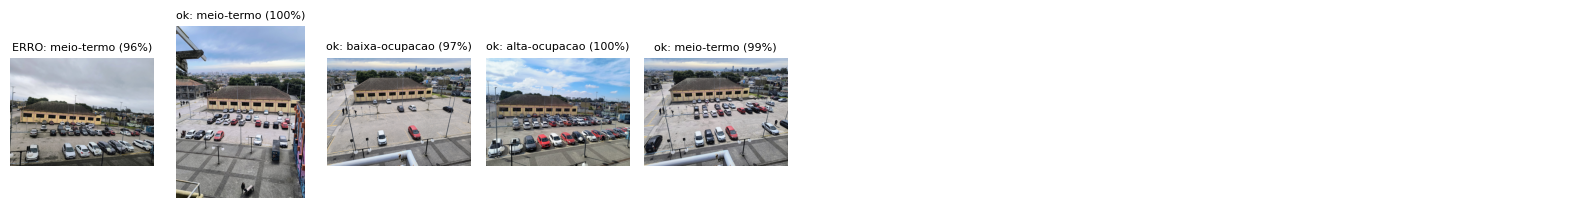

In [ ]:
amostra = random.sample(caminhos, min(20, len(caminhos)))
resultados = melhor(amostra, imgsz=224, verbose=False)

titulos = []
for caminho, r in zip(amostra, resultados):
    real, previsto = caminho.parent.name, r.names[r.probs.top1]
    marca = 'ok' if real == previsto else 'ERRO'
    titulos.append(f'{marca}: {previsto} ({float(r.probs.top1conf):.0%})')
mostrar_grade(amostra, titulos, colunas=10)

E uma imagem por vez, mostrando as três classes mais prováveis:

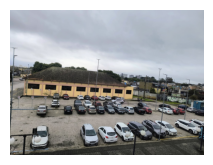

classe real: alta-ocupacao
  meio-termo: 95.6%
  alta-ocupacao: 4.4%
  baixa-ocupacao: 0.0%


In [ ]:
imagem = amostra[0]                      # troque pelo caminho de qualquer imagem
r = melhor(imagem, imgsz=224, verbose=False)[0]

plt.figure(figsize=(2.5, 2.5)); plt.imshow(Image.open(imagem).convert('RGB')); plt.axis('off'); plt.show()
print('classe real:', imagem.parent.name)
for i in r.probs.top5[:3]:
    print(f'  {r.names[i]:>10s}: {float(r.probs.data[i]):.1%}')